# 3. Part B: all five rounds (2023 - 2026 R2), repeat-taker analysis

**Questions:**
1. How high is the pass rate in each round, and why does it differ between rounds?
2. Who retakes, how many times, and how often do they pass after failing?
3. Does a previous failure itself raise the chance of failing, or does it just reflect weak scores?
4. Persistence of scores: is failure mostly stable ability or luck?

**Principles:**
- Each person is linked across rounds, and both **frequent** (1-5 times) and **infrequent** participation are analysed.
- Once a candidate passes, they stop sitting (only 17 candidates sat again after passing). A **hazard-type** analysis is therefore natural: only candidates who have not passed yet are at risk.
- **Left censoring:** rounds before 2023 are not in the data, so a "first attempt" in 2023 may not be a real first attempt.
- **Right censoring:** candidates who failed the last round cannot have come back yet.
- **Survivorship bias:** people who sit many times are those who keep failing, so "more attempts = lower pass rate" is only an association.

In [1]:
import os, sys, warnings
sys.path.insert(0, os.path.abspath('../src'))          # the notebooks live in notebooks/, the code in src/
import numpy as np
import pandas as pd
from exitexam import config as C, cleaning as cl, linking as lk, stats_utils as su, plotting as P, pipeline
from exitexam import analysis_a as A, analysis_b as B

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 220)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
P.setup()

In [2]:
clean, excluded, audit, h = pipeline.load_all()
display(audit)

exclusion_reason,rows_raw,score_missing,score_zero,result_annulled,result_unreadable,kept,ambiguous_names_kept
exam,,,,,,,
2023,6885,3,0,0,0,6882,0
2024,4381,0,0,0,0,4381,0
2025,9349,0,12,0,0,9337,0
2026-R1,6945,11,1,0,0,6933,0
2026-R2,6058,1,7,0,0,6050,0


## 3.1 Summary of each round

- pass rate with **Wilson** confidence intervals
- **first attempt** (`new`) and **retaking** (`returning`) shown separately
- **near misses** (at most 10 points below the pass mark) and **far failures** (60 or more points below)
- differences between consecutive rounds, with **Holm** correction

In [3]:
es = B.exam_summary(h)
display(es.T)
B.exam_pairwise(h)

,0,1,2,3,4
exam,2023,2024,2025,2026-R1,2026-R2
rows,6882,4381,9337,6933,6050
passes,2070,1381,3702,773,1889
pass_rate,0.301,0.315,0.396,0.111,0.312
ci_low,0.290,0.302,0.387,0.104,0.301
ci_high,0.312,0.329,0.406,0.119,0.324
mean_score,179.834,189.249,203.002,158.410,188.166
median_score,173.250,186.750,202.500,153.000,182.250
sd_score,56.520,54.718,46.859,43.636,55.461
q25,132.750,146.250,166.500,126.000,144.000


,comparison,diff_pass_rate,ci_low,ci_high,p_value,p_holm
0,2024 vs 2023,0.014,-0.003,0.032,0.105,0.105
1,2025 vs 2024,0.081,0.064,0.098,0.000,0.000
2,2026-R1 vs 2025,-0.285,-0.297,-0.273,0.000,0.000
3,2026-R2 vs 2026-R1,0.201,0.187,0.215,0.000,0.000


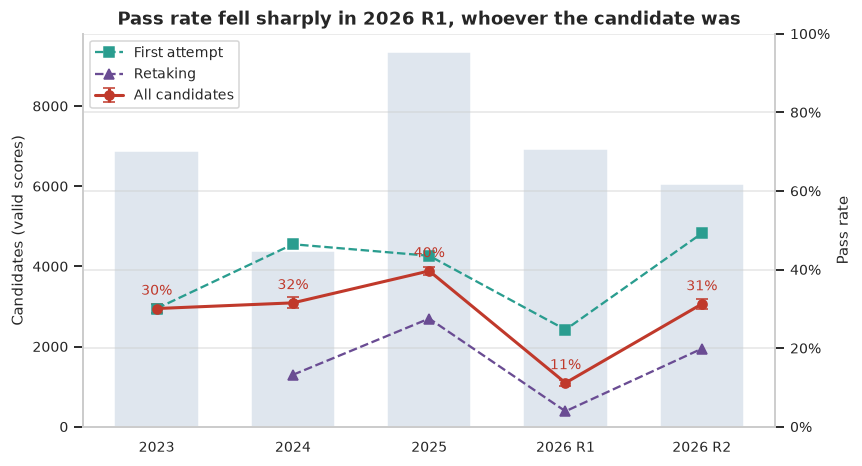

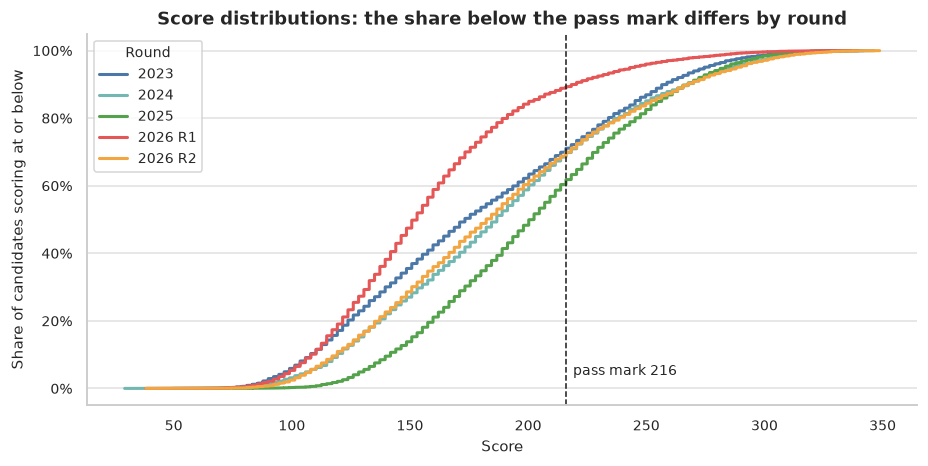

In [4]:
P.save(B.fig_overview(es), 'B01_overview')
P.save(B.fig_distribution(h), 'B02_score_distribution')

## 3.2 Composition versus rate

If a round has many retaking candidates (who pass less often), the overall pass rate falls even if the examination is unchanged. The **Kitagawa** decomposition splits the change in pass rate into two parts:
- **composition effect:** change in the share of retaking candidates
- **rate effect:** change in the pass rate within each group (a sign of round difficulty)

There is no earlier history before 2023, so the 2023 > 2024 change cannot be decomposed.

,from_exam,to_exam,pass_rate_from,pass_rate_to,total_change,composition_effect,rate_effect,share_returning_from,share_returning_to
0,2024,2025,0.315,0.396,0.081,0.051,0.030,0.449,0.242
1,2025,2026-R1,0.396,0.111,-0.285,-0.076,-0.209,0.242,0.653
2,2026-R1,2026-R2,0.111,0.312,0.201,0.010,0.191,0.653,0.613


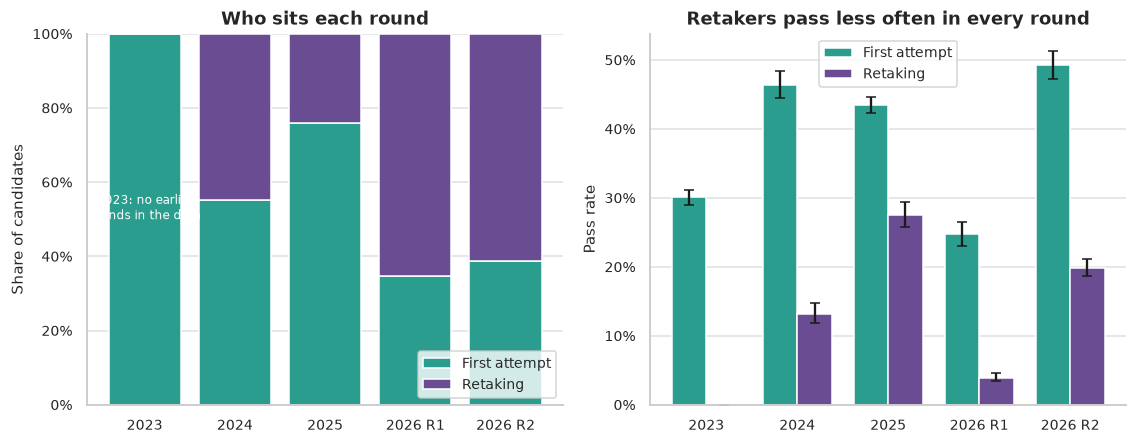

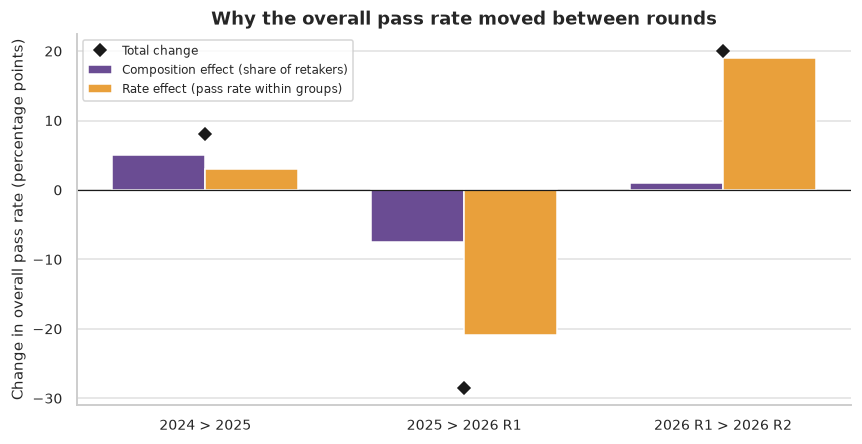

In [5]:
dec = B.decomposition(h)
display(dec)
P.save(B.fig_composition(es), 'B03_composition_new_vs_retaking')
P.save(B.fig_decomposition(dec), 'B12_decomposition')

## 3.3 Frequent and infrequent participation

How many times did each person sit (1 to 5)? What was their first score, and did they ever pass? The **2023 cohort** has the longest follow-up (5 rounds), so it gives the least truncated picture.

In [6]:
persons, dist, tests = B.participation(h)
display(dist)
display(tests)
B.attempts_for_2023_cohort(h)

,n_attempts,persons,share_of_persons,ever_passed,mean_first_score,median_first_score,share_first_attempt_near_miss
0,1,13529,0.640,0.592,212.875,225.000,0.050
1,2,3952,0.187,0.273,162.856,166.500,0.086
2,3,2719,0.129,0.233,165.478,168.750,0.098
3,4,652,0.031,0.081,149.176,148.500,0.044
4,5,277,0.013,0.116,151.124,153.000,0.029


,test,statistic,p_value
0,Kruskal-Wallis: first-attempt score differs by...,"4,059.756",0.000
1,Spearman rho: number of attempts vs first-atte...,-0.429,NaN


,n_attempts,persons,ever_passed,mean_first_score,share
0,1,3965,0.518,199.655,0.576
1,2,1309,0.316,158.294,0.190
2,3,888,0.339,149.878,0.129
3,4,443,0.070,144.076,0.064
4,5,277,0.116,151.124,0.040


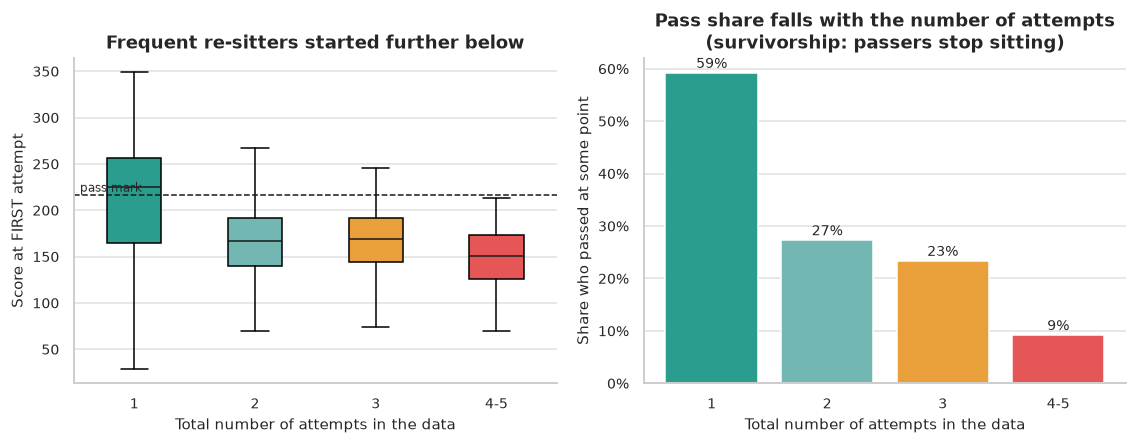

In [7]:
P.save(B.fig_attempts(persons, dist), 'B10_number_of_attempts')

## 3.4 After a failure: coming back and passing

Every failed candidate is followed to the next round: **did they come back?** and **did they pass?** Pooled figures use a **person-cluster bootstrap**, because one person can appear in several transitions.

In [8]:
tr, F = B.transitions(h)
tr

,transition,failed,returned,return_rate,ret_low,ret_high,pass_given_return,pass_low,pass_high,pass_rate_among_all_failed,mean_score_change,returned_in_any_later_round
0,2023 > 2024,4812,1952,0.406,0.392,0.420,0.127,0.113,0.142,0.051,10.598,0.603
1,2024 > 2025,3000,1617,0.539,0.521,0.557,0.302,0.281,0.325,0.163,33.896,0.663
2,2025 > 2026-R1,5635,4008,0.711,0.699,0.723,0.036,0.031,0.043,0.026,-23.786,0.776
3,2026-R1 > 2026-R2,6160,3173,0.515,0.503,0.528,0.222,0.207,0.236,0.114,30.102,0.515
4,"ALL (pooled, cluster bootstrap)",19607,10750,0.548,0.541,0.556,0.147,0.141,0.154,0.081,7.040,0.634


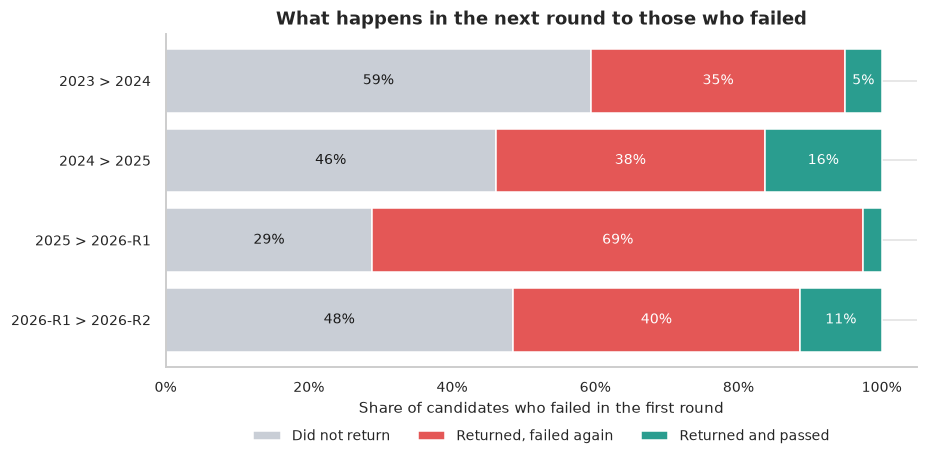

,band,rows_return,persons_return,passes_return,rate_return,ci_low_return,ci_high_return,rows_pass,persons_pass,passes_pass,rate_pass,ci_low_pass,ci_high_pass
0,60+ below,9532,6930,4690,0.492,0.482,0.504,4690,3469,194,0.041,0.036,0.047
1,30-60 below,5358,4564,3170,0.592,0.578,0.605,3170,2748,572,0.180,0.168,0.193
2,10-30 below,3355,2960,2094,0.624,0.607,0.641,2094,1879,564,0.269,0.250,0.287
3,0-10 below,1362,1290,796,0.584,0.559,0.610,796,753,255,0.320,0.290,0.351


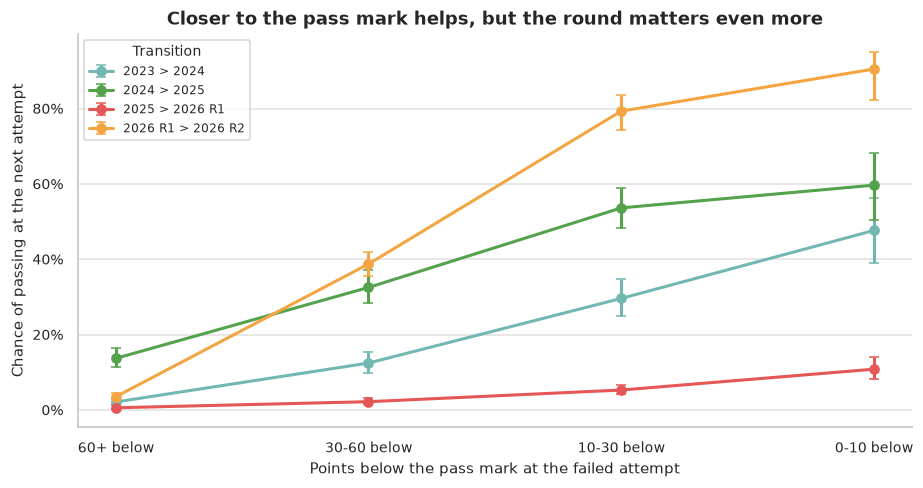

In [9]:
P.save(B.fig_transitions(F), 'B04_after_failure')
per, pooled = B.gap_bands(F)
display(pooled)
P.save(B.fig_gap(per), 'B05_distance_to_pass_mark')

**Near misses:** candidates who failed narrowly have a good chance, but the chance **differs strongly between rounds** (after 2025 even near misses passed only about 11% in 2026 R1, whereas after 2026 R1 about 90% passed in 2026 R2). The difficulty of the round matters more than how close the candidate was to the pass mark.

## 3.5 Number of previous failures

First descriptive, then regression models. **M2** controls for round and field. **M3** is restricted to retaking candidates and adds the **distance below the pass mark at the last attempt**.

**Caution:** the "3+ failures" group are people who kept failing. This group is selected, so the odds ratio describes an association, not an effect of failing.

,prior_failures,rows,persons,passes,rate,ci_low,ci_high
0,0,21127,21127,8020,0.380,0.373,0.387
1,1,7584,7584,1062,0.140,0.133,0.148
2,2,3647,3647,633,0.174,0.161,0.185
3,3+,1206,929,85,0.070,0.057,0.085


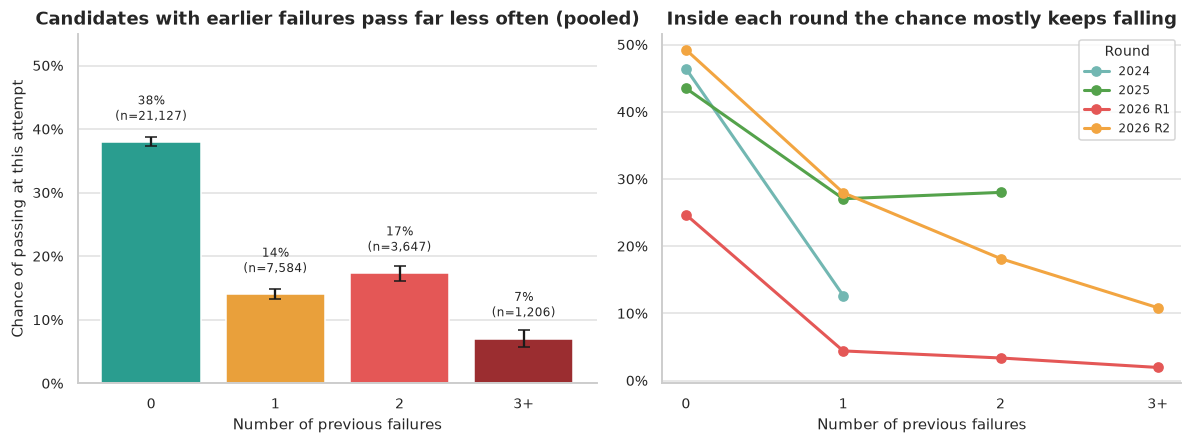

In [10]:
pf_pooled, pf_round = B.prior_fails_table(h)
display(pf_pooled)
P.save(B.fig_prior_fails(pf_pooled, pf_round), 'B06_previous_failures')

In [11]:
models, r_all, r_ret = B.hazard_models(h)
mt = B.models_to_table(models)
mt[['model', 'term', 'odds_ratio', 'or_low', 'or_high', 'p_value', 'n_rows', 'n_persons', 'mcfadden_r2']]

,model,term,odds_ratio,or_low,or_high,p_value,n_rows,n_persons,mcfadden_r2
0,M1 round + field,const,0.768,0.735,0.804,0.000,33564,21127,0.055
1,M1 round + field,round[2023],0.667,0.625,0.711,0.000,33564,21127,0.055
2,M1 round + field,round[2024],0.680,0.632,0.733,0.000,33564,21127,0.055
3,M1 round + field,round[2026-R1],0.195,0.179,0.212,0.000,33564,21127,0.055
4,M1 round + field,round[2026-R2],0.591,0.553,0.632,0.000,33564,21127,0.055
5,M1 round + field,field[stomatology],0.511,0.477,0.547,0.000,33564,21127,0.055
6,M2 + number of previous failures,const,0.980,0.935,1.027,0.395,33564,21127,0.098
7,M2 + number of previous failures,round[2023],0.515,0.481,0.551,0.000,33564,21127,0.098
8,M2 + number of previous failures,round[2024],0.835,0.768,0.907,0.000,33564,21127,0.098
9,M2 + number of previous failures,round[2026-R1],0.306,0.280,0.336,0.000,33564,21127,0.098


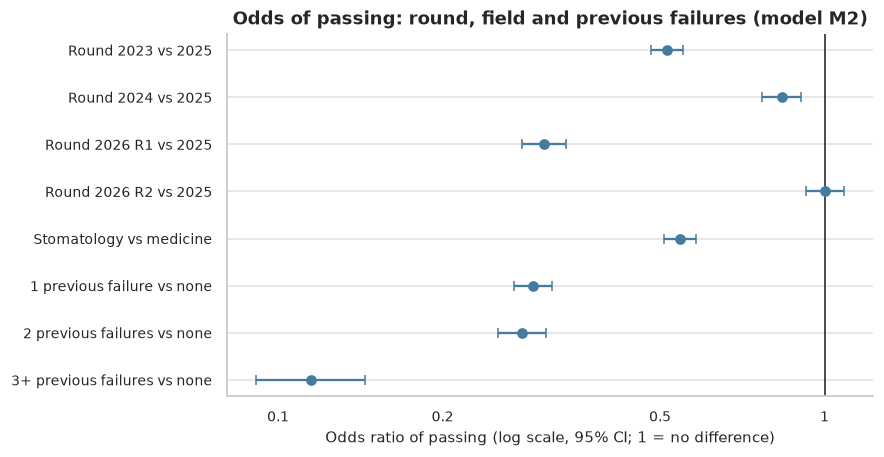

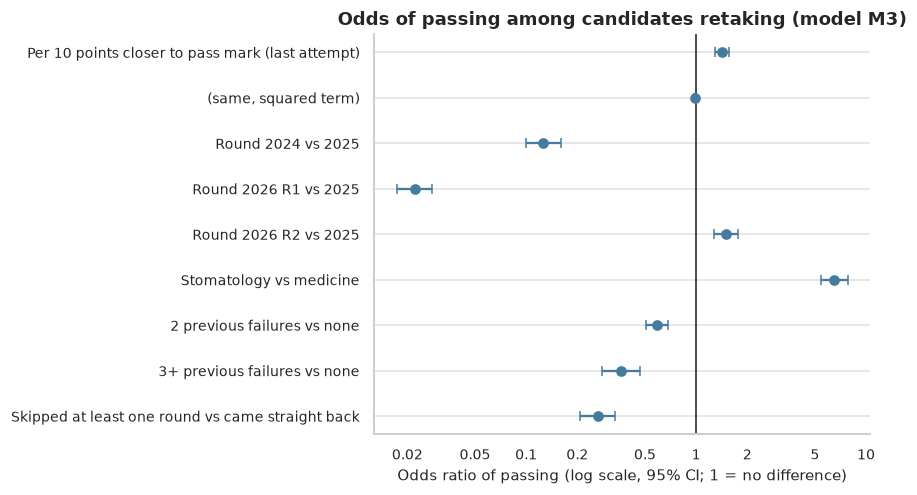

In [12]:
names = list(models)
P.save(B.fig_forest({names[1]: models[names[1]]}, 'Odds of passing: round, field and previous failures (model M2)'), 'B07_odds_ratios_all_candidates')
P.save(B.fig_forest({n: models[n] for n in names[2:]}, 'Odds of passing among candidates retaking (model M3)'), 'B08_odds_ratios_returners')

## 3.6 Persistence of scores (stable ability versus luck)

If scores in two rounds are strongly correlated (r about 0.6-0.8), failure is largely **persistent** (ability or preparation). The **mean change** reflects round difficulty: from 2025 to 2026 R1 retaking candidates scored on average **about 24 points lower**, even though "regression to the mean" should push them up. This is strong evidence of the difficulty of 2026 R1.

,transition,persons,pearson_r,r_low,r_high,spearman_rho,slope_next_on_prev,mean_change,mean_change_low,mean_change_high,sd_prev,sd_next
0,2023 > 2024,1967,0.741,0.721,0.761,0.756,0.894,10.489,9.245,11.733,34.498,41.589
1,2024 > 2025,1617,0.595,0.562,0.626,0.586,0.665,33.896,32.346,35.447,33.187,37.071
2,2025 > 2026-R1,4008,0.644,0.626,0.662,0.674,0.796,-23.786,-24.586,-22.985,26.755,33.040
3,2026-R1 > 2026-R2,3173,0.825,0.813,0.835,0.829,1.232,30.102,29.201,31.002,29.529,44.120


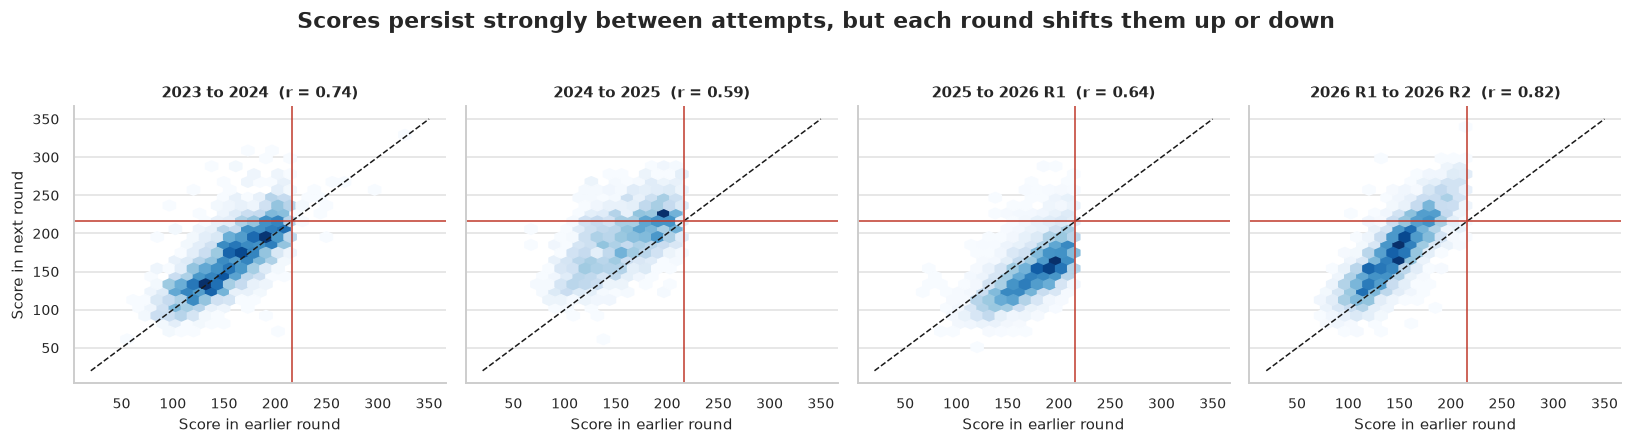

In [13]:
rt = B.retest(h)
display(rt)
P.save(B.fig_retest(h), 'B11_score_persistence')

## 3.7 Entry cohorts

Everyone who first appeared in a given round forms a cohort. By each later round, what share has passed? These figures are not truncated, because the whole cohort is in view.

,entry_round,failed_first_attempt,came_back,came_back_share,eventually_passed,eventually_passed_share,ep_low,ep_high,never_came_back_and_not_passed
0,2023,4812,2901,0.603,761,0.158,0.148,0.169,1911
1,2024,1293,804,0.622,263,0.203,0.182,0.226,489
2,2025,4000,3094,0.773,457,0.114,0.105,0.124,906
3,2026-R1,1814,785,0.433,299,0.165,0.148,0.183,1029


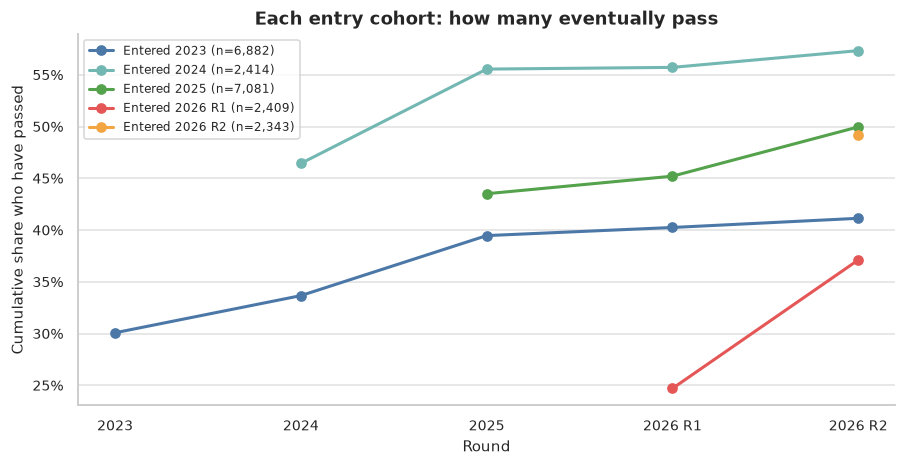

In [14]:
cum, cohort_tab = B.cohorts(h)
display(cohort_tab)
P.save(B.fig_cohorts(cum), 'B09_entry_cohorts')

## 3.8 Sensitivity analysis of the linkage

Do the results change if the linkage is relaxed (accepting small typos in the grandfather's name)?

In [15]:
sens = B.linkage_sensitivity(clean, h, models)
display(sens)
print('extra links:', sens.attrs['extra_links'])

,linking_rule,persons,return_rate_after_fail,pass_given_return,OR_1_prev_fail,OR_2_prev_fails,OR_3plus_prev_fails
0,exact name+field (main),21129,0.548,0.147,0.293,0.279,0.115
1,typo-tolerant grandfather name,20920,0.557,0.148,0.290,0.279,0.108


extra links: 209


## 3.9 Supplementary

The 2023 file contains the year of graduation. Graduates of 1399 had a lower pass rate (about 18%) than graduates of 1400 (about 34%). This is a single round, so it is only descriptive.

**Note:** the 2024 file's gender column is all male (4,380 of 4,381), so gender cannot be analysed.

In [16]:
sup = B.supplementary(h)
sup['S2_graduation_year_2023']

,grad_year,rows,passes,mean_score,pass_rate,ci_low,ci_high
3,1397,41,11,157.555,0.268,0.157,0.419
4,1398,90,13,153.275,0.144,0.086,0.232
5,1399,1070,188,157.433,0.176,0.154,0.200
6,1400,3388,1165,186.371,0.344,0.328,0.360
7,1401,2276,689,182.215,0.303,0.284,0.322


## 3.10 Limitations (to state in the paper)

- All of this is **observational**. A previous failure is not treated as a cause.
- The difficulty of 2026 R1 (11% pass rate) may be due to the paper, the rules or a change in administration. The data do not contain the reason; check the examination authority's administrative information (number and type of questions, timing).
- 2026 R2 contains medicine only.
- Earlier attempts before 2023 are not visible.
- Candidates who do not return (dropout) may have passed elsewhere, given up or left the country; we do not know the reason.